# 09 · 外部検証：EGD・Japan での性能、出力整合、不確かさ

LOSO-A / LOSO-B の 6 モデル（各 3 seed）を、学習に一度も使っていない 2 つの外部コホートで推論した結果を読む。
推論は `scripts/eval_external.py`（Raiden、GPU）で済んでいて、この notebook は `predictions.csv` だけを読む（GPU 不要）。

| コホート | 症例 | IDH 変異 | 備考 |
|---|---|---|---|
| EGD（オランダ、公開） | 467 | 155（33.2%） | 4 シーケンスすべてそろう。年齢欠損 42 例 |
| Japan（旧 NCC、10 施設） | 620 | 175（28.2%） | 6 mm 厚の 2D 臨床画像。4 シーケンスそろいは 547 例 |

問いは 3 つ。

1. **判別と較正**：AUC は保たれるか。予測の平均は実際の変異率と合うか
2. **出力整合**（ラベル 0 例の切片補正、notebook 06・07 の方法）は、本物の外部施設でも較正を直せるか。
   各 LOSO モデルは自分の学習施設で当てた π(年齢, 疑い) と inner-val の基準をそのまま使い、外部コホートを「新しい施設」として扱う
3. **不確かさ**：Beta 出力の S = α + β（証拠の量）は、不正解の症例で小さく（＝分布の裾が広く）なっているか

「疑い」は WHO 2016 の grade 4 を 1、grade 2/3 を 0 にした代用である（06 と同じ）。
Japan の WHO 2021 grade は IDH 野生型の分子マーカーで決まる部分があり、正解ラベルが混ざるので主解析には使わない。

ロジックは `scripts/external_followup.py` にある。この notebook は呼んで記録するだけ。
症例ごとの値は出力しない（集計値と図だけ）。

In [1]:
runs       = ["foldA_s0", "foldA_s1", "foldA_s2", "foldB_s0", "foldB_s1", "foldB_s2"]
cohorts    = ["EGD", "Japan"]
grade_col  = "who_grade"         # WHO 2016. Japan's who_grade_2021 leaks IDH-wt markers into pi
reps       = 50                  # draws per run for the first-N evaluation (as in 06/07)
seed       = 0
expected_n = {"EGD": 467, "Japan": 620}   # case counts from the data-management reports
eval_dir   = None                # default: <external_metadata_dir>/../external_eval
out_json   = "results/external_validation.json"
out_md     = "results/external_validation.md"
fig_dir    = "results/figures"

In [2]:
import os, sys, json
from pathlib import Path
_root = Path.cwd()
while not (_root / "data" / "metadata").exists():
    _root = _root.parent
os.chdir(_root); sys.path.insert(0, str(_root)); sys.path.insert(0, str(_root / "scripts"))
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from openidh_model.utils.paths import load_paths
from openidh_model.eval.metrics import compute_metrics
import external_followup as ef

figs = {k: Path(fig_dir) / f"external_{k}.png" for k in ("reliability", "n_curve", "uncertainty")}
for f in (out_json, out_md, *figs.values()):
    assert not Path(f).exists() or os.environ.get("EV_OVERWRITE") == "1", \
        f"{f} exists — refusing to overwrite (set EV_OVERWRITE=1)"
Path(fig_dir).mkdir(parents=True, exist_ok=True)

paths = load_paths()             # OPENIDH_PATHS (configs/paths.hpc.yaml on Raiden)
print("external_metadata_dir:", paths.external_metadata_dir)

external_metadata_dir: /home/satoc/data/OpenIDH/metadata


## 0. 読み込みと検算

- **症例数**：各ランの症例数が EGD 467・Japan 620 であること
- **AUC の一致**：ここで `predictions.csv` から計算し直した AUC が、`eval_external.py` の `summary.json` と一致すること（同じ予測なので差は 0 のはず）

In [3]:
a = ef.analyse(paths, runs, cohorts, grade_col, reps, seed, eval_dir)
pred = a["pred"]
n_cases = pred.groupby(["run", "role"]).size().unstack()
display(n_cases)
assert all((n_cases[c] == expected_n[c]).all() for c in cohorts if c in expected_n), "症例数が報告書と違う"

summ_ext = json.loads((a["eval_dir"] / "summary.json").read_text())
d_auc = max(abs(compute_metrics(g.alpha, g.beta, g.y_true)["auc"] - summ_ext["per_run"][r][c]["all"]["auc"])
            for (r, c), g in pred.groupby(["run", "role"]))
print(f"max |ΔAUC| vs summary.json = {d_auc:.1e}")
assert d_auc < 1e-9
print("cases without age (left out of the output-matching part):", a["dropped"])
checks = {"n_cases": n_cases.to_dict(), "max_abs_auc_diff_vs_summary": d_auc, "dropped_no_age": a["dropped"]}

role,EGD,Japan
run,,
foldA_s0,467,620
foldA_s1,467,620
foldA_s2,467,620
foldB_s0,467,620
foldB_s1,467,620
foldB_s2,467,620


max |ΔAUC| vs summary.json = 0.0e+00
cases without age (left out of the output-matching part): {'EGD': 42, 'Japan': 0}


## 1. 外部での性能（補正前）

3 seed の平均 ± sd。`own test` は各モデルの元の LOSO test（参考）。平均予測と実際の変異率の差が、較正のずれの大きさを表す。

In [4]:
own = pd.concat([pd.read_csv(a["runs_dir"] / r / "predictions.csv").query("role == 'test'").assign(run=r, role="own test")
                 for r in runs])
rows = []
for (r, c), g in pd.concat([own, pred]).groupby(["run", "role"]):
    m = compute_metrics(g.alpha, g.beta, g.y_true)
    rows.append({"unit": ef.UNITS[r.startswith("foldB")], "cohort": c, "run": r, "n": len(g),
                 "rate": g.y_true.mean(), "mean_p": g.p_hat.mean(),
                 **{k: m[k] for k in ("auc", "auprc", "ece", "nll", "brier")}})
perf_runs = pd.DataFrame(rows)
perf = (perf_runs.groupby(["unit", "cohort"], sort=False)
        .agg(n=("n", "first"), rate=("rate", "first"), mean_p=("mean_p", "mean"),
             auc=("auc", "mean"), auc_sd=("auc", "std"), ece=("ece", "mean"), ece_sd=("ece", "std"),
             nll=("nll", "mean"), brier=("brier", "mean")))
display(perf.round(3))

n   rate  mean_p    auc  auc_sd    ece  ece_sd    nll  brier
unit   cohort                                                                  
LOSO-A EGD       467  0.332   0.216  0.862   0.016  0.120   0.028  0.508  0.160
       Japan     620  0.282   0.163  0.808   0.037  0.128   0.010  0.541  0.169
       own test  501  0.206   0.126  0.856   0.021  0.082   0.025  0.400  0.122
LOSO-B EGD       467  0.332   0.126  0.861   0.013  0.206   0.020  0.647  0.206
       Japan     620  0.282   0.067  0.839   0.042  0.217   0.022  0.748  0.221
       own test  619  0.284   0.123  0.854   0.019  0.162   0.018  0.559  0.177

## 2. 出力整合（全例）

各手法の切片 b を全例に足したときの較正。値は 3 seed の平均 ± sd。
`出力整合（oracle 係留）` は真の変異率に合わせたもので、ラベルを使う上限。`全例ラベル切片` は全例のラベルで当てた切片（これも上限で、06 の検算どおり oracle 係留と一致するはず）。

In [5]:
full = a["full"].assign(method_ja=lambda d: d["method"].map(ef.om.METHODS_FULL))
order = list(ef.om.METHODS_FULL.values())
tab = (full.groupby(["unit", "method_ja"], sort=False)
       .agg(n=("n", "first"), pi_true=("pi_true", "mean"), pi_cov=("pi_cov_test", "mean"),
            b=("b", "mean"), b_sd=("b", "std"), ece=("ece", "mean"), ece_sd=("ece", "std"),
            nll=("nll", "mean"), brier=("brier", "mean")))
display(tab.round(3))
display(full.pivot_table(index="unit", columns="method_ja", values="ece", sort=False)[order].round(3))
d_or = (full[full.method == "e_om_oracle"].set_index(["run", "unit"]).b
        - full[full.method == "f_label_mle"].set_index(["run", "unit"]).b).abs().max()
print(f"max |b(oracle anchor) - b(all-label MLE)| = {d_or:.1e}")
checks["max_abs_b_oracle_vs_mle"] = float(d_or)
clipped = full[full.status != "ok"]
print("clipped solves:", len(clipped))

n  pi_true  pi_cov      b   b_sd    ece  ece_sd    nll  brier
unit           method_ja                                                                       
LOSO-A → EGD   補正なし             425    0.351   0.314  0.000  0.000  0.134   0.030  0.538  0.170
               比方式（年齢のみ）        425    0.351   0.314  0.182  0.000  0.116   0.032  0.516  0.164
               比方式（年齢+疑い）       425    0.351   0.314  0.743  0.000  0.070   0.024  0.470  0.152
               出力整合（年齢+疑い）      425    0.351   0.314  0.856  0.315  0.066   0.011  0.461  0.149
               出力整合（年齢のみ）       425    0.351   0.314 -0.068  0.353  0.141   0.004  0.543  0.172
               出力整合（oracle 係留）  425    0.351   0.314  1.152  0.301  0.080   0.010  0.455  0.148
               全例ラベル切片          425    0.351   0.314  1.152  0.301  0.080   0.010  0.455  0.148
LOSO-A → Japan 補正なし             620    0.282   0.310  0.000  0.000  0.128   0.010  0.541  0.169
               比方式（年齢のみ）        620    0.282   0.310  0.187  0.000  0.113   0.009  0.520  0.164
               比方式（年齢+疑い）       620    0.282   0.310  0.725  0.000  0.079   0.008  0.480  0.153
               出力整合（年齢+疑い）      620    0.282   0.310  1.287  0.175  0.072   0.014  0.474  0.151
               出力整合（年齢のみ）       620    0.282   0.310  0.536  0.142  0.082   0.004  0.490  0.156
               出力整合（oracle 係留）  620    0.282   0.310  1.089  0.166  0.074   0.020  0.471  0.150
               全例ラベル切片          620    0.282   0.310  1.089  0.166  0.074   0.020  0.471  0.150
LOSO-B → EGD   補正なし             425    0.351   0.302  0.000  0.000  0.223   0.020  0.680  0.218
               比方式（年齢のみ）        425    0.351   0.302  0.482  0.000  0.177   0.026  0.583  0.190
               比方式（年齢+疑い）       425    0.351   0.302  1.179  0.000  0.108   0.015  0.488  0.159
               出力整合（年齢+疑い）      425    0.351   0.302  1.510  0.252  0.086   0.010  0.461  0.149
               出力整合（年齢のみ）       425    0.351   0.302  0.519  0.245  0.174   0.000  0.574  0.188
               出力整合（oracle 係留）  425    0.351   0.302  1.833  0.249  0.070   0.022  0.453  0.146
               全例ラベル切片          425    0.351   0.302  1.833  0.249  0.070   0.022  0.453  0.146
LOSO-B → Japan 補正なし             620    0.282   0.294  0.000  0.000  0.217   0.022  0.748  0.221
               比方式（年齢のみ）        620    0.282   0.294  0.527  0.000  0.184   0.031  0.642  0.201
               比方式（年齢+疑い）       620    0.282   0.294  1.142  0.000  0.138   0.032  0.545  0.177
               出力整合（年齢+疑い）      620    0.282   0.294  2.210  0.368  0.099   0.019  0.469  0.150
               出力整合（年齢のみ）       620    0.282   0.294  1.439  0.398  0.124   0.020  0.505  0.166
               出力整合（oracle 係留）  620    0.282   0.294  2.137  0.372  0.103   0.021  0.469  0.150
               全例ラベル切片          620    0.282   0.294  2.137  0.372  0.103   0.021  0.469  0.150

method_ja,補正なし,比方式（年齢のみ）,比方式（年齢+疑い）,出力整合（年齢+疑い）,出力整合（年齢のみ）,出力整合（oracle 係留）,全例ラベル切片
unit,,,,,,,
LOSO-A → EGD,0.134,0.116,0.070,0.066,0.141,0.080,0.080
LOSO-A → Japan,0.128,0.113,0.079,0.072,0.082,0.074,0.074
LOSO-B → EGD,0.223,0.177,0.108,0.086,0.174,0.070,0.070
LOSO-B → Japan,0.217,0.184,0.138,0.099,0.124,0.103,0.103


max |b(oracle anchor) - b(all-label MLE)| = 3.3e-08
clipped solves: 0


## 3. 信頼度図

対角線が完全較正。対角線より上は過小評価（予測が低すぎる）。点線は実際の変異率。
3 seed の症例をまとめて 10 等幅ビンにした。出力整合は全例で解いた切片を使う。

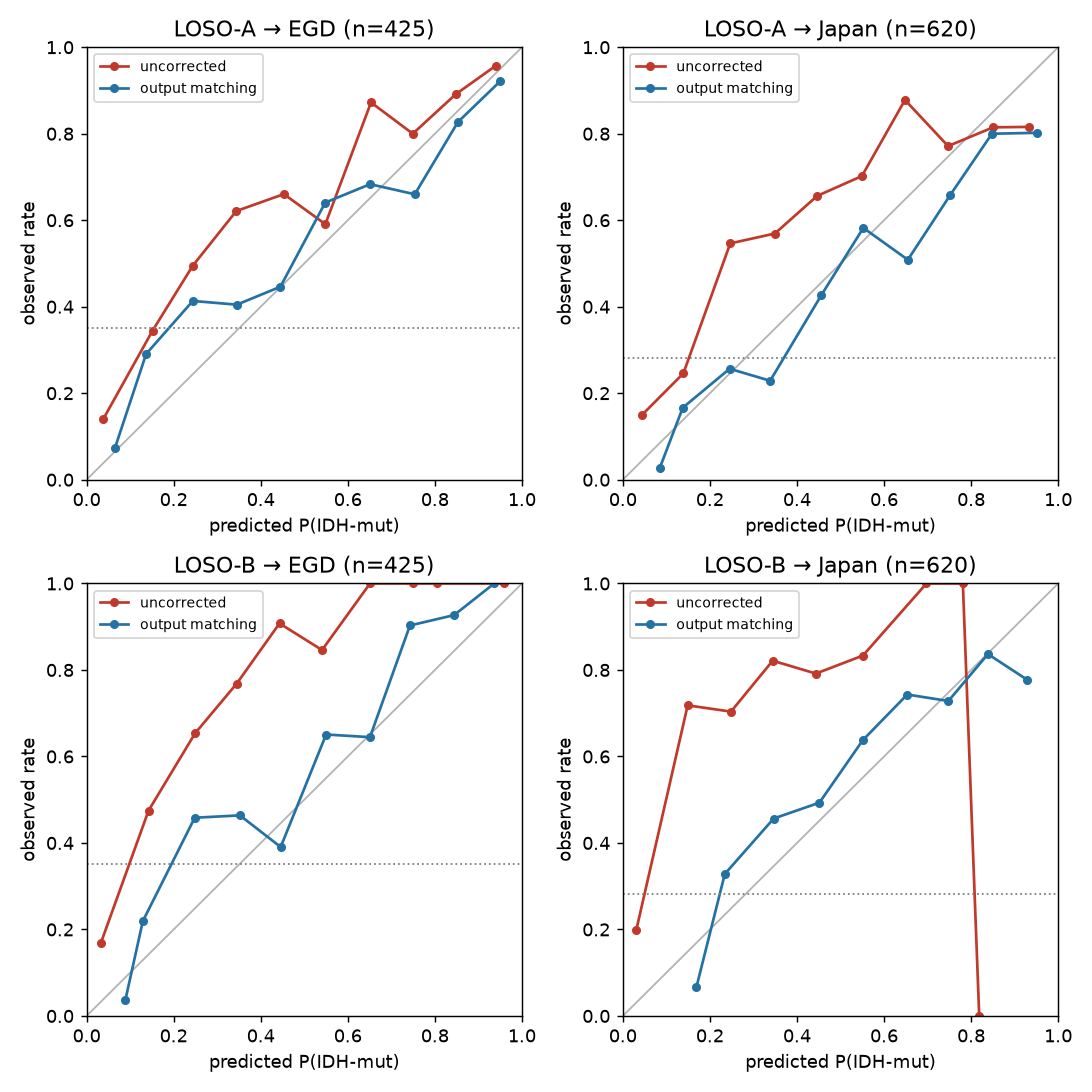

In [6]:
fig = ef.plot_reliability(a, figs["reliability"]); plt.close(fig)
display(Image(filename=str(figs["reliability"])))

## 4. 最初の N 例だけで補正する場合

新しい施設で最初に集まった N 例（ラベルなし）だけで切片を決め、残りの症例で ECE を測る（06 の評価 2、07 のゲートと同じ手順。
N 例は各ランで `reps` 回抜き直す）。`label` は同じ N 例のラベルで切片を当てた場合（ラベルありの比較対象）。
ゲートは |b̂| > k × SE（k = 2.5、SE は N 例内のブートストラップ）のときだけ補正する。P(害) = 補正しないより ECE が 0.01 を超えて悪化した割合。

ece_mean                      fire_rate        p_harm_tol                     
method                label            om            label     om      label            om       
gate                   none    2.5   none    2.5       2.5    2.5       none    2.5   none    2.5
unit           n                                                                                 
LOSO-A → EGD   20     0.103  0.130  0.099  0.122     0.260  0.220      0.160  0.067  0.140  0.007
               50     0.085  0.104  0.082  0.102     0.593  0.507      0.040  0.040  0.020  0.000
               100    0.078  0.084  0.081  0.093     0.853  0.680      0.013  0.013  0.000  0.000
               200    0.084  0.084  0.083  0.085     0.993  0.927      0.007  0.007  0.007  0.007
LOSO-A → Japan 20     0.100  0.129  0.088  0.112     0.227  0.493      0.167  0.113  0.060  0.060
               50     0.084  0.103  0.082  0.086     0.587  0.893      0.033  0.033  0.033  0.033
               100    0.078  0.082  0.079  0.079     0.907  1.000      0.007  0.007  0.007  0.007
               200    0.079  0.079  0.078  0.078     0.987  1.000      0.007  0.007  0.000  0.000
LOSO-B → EGD   20     0.099  0.141  0.096  0.121     0.653  0.733      0.013  0.013  0.007  0.007
               50     0.086  0.090  0.087  0.089     0.967  0.967      0.000  0.000  0.000  0.000
               100    0.079  0.079  0.087  0.087     1.000  1.000      0.000  0.000  0.000  0.000
               200    0.085  0.085  0.090  0.090     1.000  1.000      0.000  0.000  0.000  0.000
LOSO-B → Japan 20     0.113  0.154  0.105  0.108     0.600  0.960      0.000  0.000  0.000  0.000
               50     0.098  0.099  0.098  0.098     0.987  1.000      0.000  0.000  0.000  0.000
               100    0.094  0.094  0.097  0.097     1.000  1.000      0.000  0.000  0.000  0.000
               200    0.098  0.098  0.100  0.100     1.000  1.000      0.000  0.000  0.000  0.000

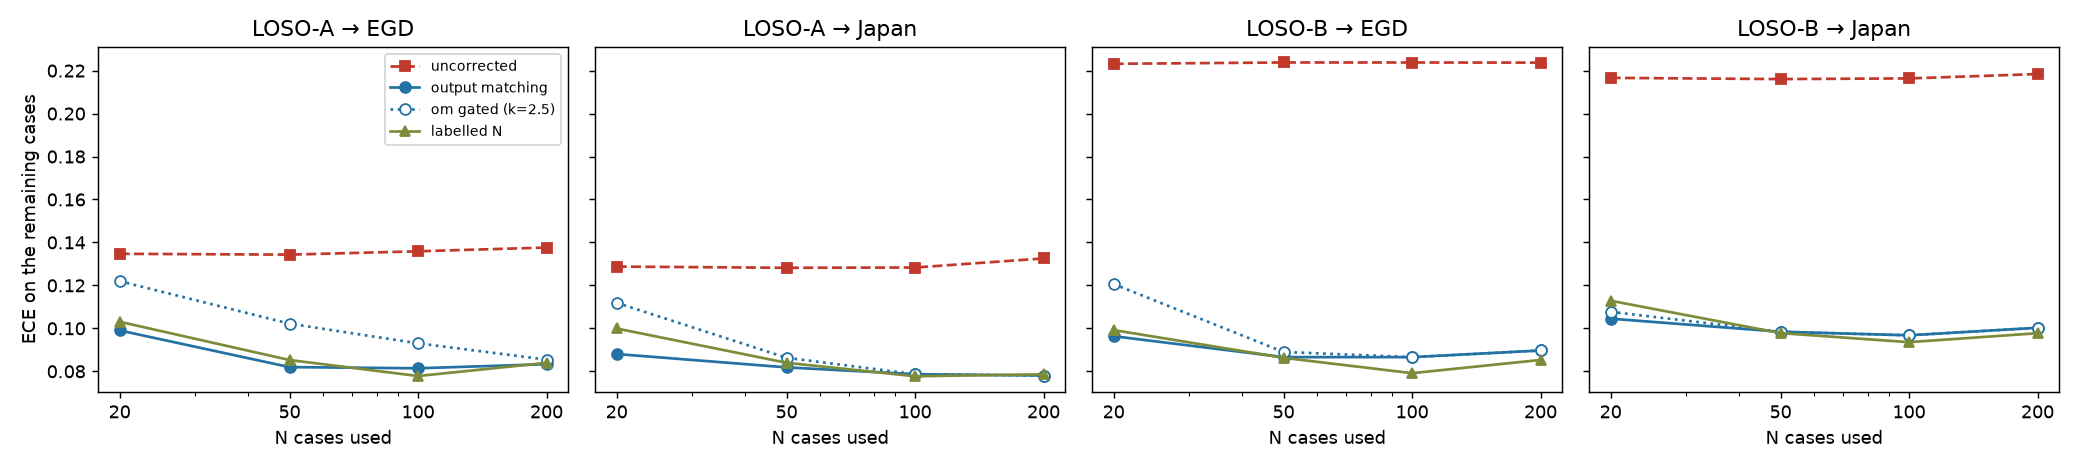

In [7]:
g = a["gsum"]
view = g[(g.method.isin(["om", "label"])) & (g.gate.isin(["none", str(ef.K)]))]
display(view.pivot_table(index=["unit", "n"], columns=["method", "gate"],
                         values=["ece_mean", "fire_rate", "p_harm_tol"], sort=False).round(3))
fig = ef.plot_n_curve(a, figs["n_curve"]); plt.close(fig)
display(Image(filename=str(figs["n_curve"])))

## 5. 不確かさ：不正解の症例で分布の裾は広がっているか

Beta(α, β) の S = α + β が証拠の量。**S が小さい = 分布が広い（裾が重い）**。正解・不正解は p̂ > 0.5 で判定する。

- `raw` は補正前、`om` は出力整合の切片を足した後（S は切片で変わらないが、どの症例が不正解かが変わる）
- AUROC(S)：S で正解と不正解をどれだけ分けられるか。0.5 なら S は役に立たず、0.5 より大きければ不正解のほうが S が小さい
- Spearman(S, |y − p̂|)：負なら、誤差が大きいほど S が小さい
- S の三分位ごとの AUC：S が高い症例ほど判別が良いなら、S は「どの症例を信じてよいか」の目印になる

注意：証拠が少ない症例は p̂ が 0.5 に寄りやすい。そのため、正解・不正解で S が違うことの一部は、この見かけ上の関係でも生じる。

n    acc  n_wrong  S_median  S_right  S_wrong  auroc_S_right  spearman_S_err  auc_S_low  auc_S_mid  auc_S_high
unit   cohort   after                                                                                                                    
LOSO-A own test raw    501.0  0.834   83.000    44.798   46.630   35.745          0.767          -0.669      0.743      0.774       0.750
       EGD      raw    467.0  0.780  102.667    41.649   43.776   36.239          0.703          -0.613      0.747      0.838       0.843
                om     467.0  0.805   91.000    41.649   43.164   36.706          0.670          -0.538      0.747      0.838       0.843
       Japan    raw    620.0  0.777  138.333    40.743   43.619   30.937          0.759          -0.661      0.686      0.727       0.701
                om     620.0  0.797  126.000    40.743   43.137   31.645          0.732          -0.535      0.686      0.727       0.701
LOSO-B own test raw    619.0  0.739  161.333    51.961   55.105   44.076          0.738          -0.699      0.794      0.749       0.843
       EGD      raw    467.0  0.697  141.333    50.684   54.115   43.486          0.756          -0.668      0.776      0.813       0.814
                om     467.0  0.794   96.333    50.684   52.754   44.354          0.688          -0.593      0.776      0.813       0.814
       Japan    raw    620.0  0.723  172.000    54.862   58.178   47.813          0.750          -0.723      0.735      0.780       0.689
                om     620.0  0.791  129.333    54.862   57.013   48.728          0.714          -0.662      0.735      0.780       0.689

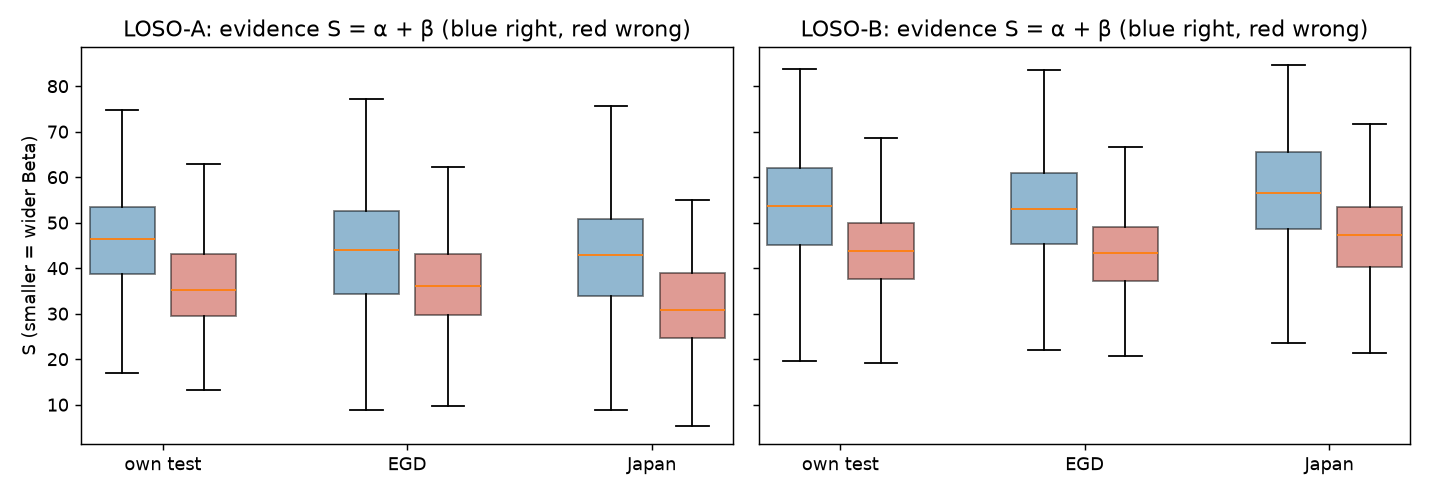

In [8]:
unc = a["unc"].assign(unit=lambda d: np.where(d.run.str.startswith("foldB"), "LOSO-B", "LOSO-A"))
cols = ["n", "acc", "n_wrong", "S_median", "S_right", "S_wrong", "auroc_S_right", "spearman_S_err",
        "auc_S_low", "auc_S_mid", "auc_S_high"]
display(unc.groupby(["unit", "cohort", "after"], sort=False)[cols].mean().round(3))
fig = ef.plot_uncertainty(a, figs["uncertainty"]); plt.close(fig)
display(Image(filename=str(figs["uncertainty"])))

## 6. 読み方

結論はこのセルの上の数字から書く。見るべき点：

1. **判別**：外部の AUC は元の LOSO test（A 0.856 / B 0.854）と比べてどうか。Japan（6 mm 厚）でどれだけ下がるか
2. **較正のずれの向き**：平均予測は実際の変異率より低いか（過小評価）。学習時の変異率が低い LOSO-B のほうがずれは大きいか
3. **出力整合**：ラベル 0 例で、全例ラベル切片（上限）にどこまで近づくか。比方式より良いか。π̂_cov は真の変異率に近いか
   （外部施設では「疑い」の分布も年齢の分布も学習施設と違うので、π(年齢, 疑い) の外挿が効いているかの検証になる）
4. **N 例**：N = 20 でゲートはどれだけ発火するか。P(害) は 10% 未満か。ラベルあり N 例と比べてどうか
5. **不確かさ**：外部でも、不正解の S は正解より小さいか（AUROC(S) > 0.5、Spearman < 0）。その差は元の LOSO test と同じくらい保たれているか。
   外部（特に Japan）では全体の S が下がっているか（見たことのない画像では証拠が減る、という望ましい振る舞い）

## 7. 保存

In [9]:
res = {"checks": checks, **ef.to_json(a), "performance": perf_runs.to_dict(orient="records")}
Path(out_json).write_text(json.dumps(res, indent=1, ensure_ascii=False, default=float))
md_text = "# 外部検証（EGD・Japan）— 結果要約\n\n"
md_text += (f"notebook: `notebooks/09_external_validation.ipynb`。検算：AUC は summary.json と一致（最大差 {d_auc:.0e}）、"
            f"oracle 係留と全例ラベル切片の差 {d_or:.0e}。年齢欠損で出力整合から除いた症例：{a['dropped']}。\n\n")
md_text += "## 外部での性能（補正前、3 seed 平均）\n\n" + ef.df_to_md(perf.round(3)) + "\n\n"
md_text += ef.report(a["full"], a["gsum"], a["unc"], a["dropped"], grade_col, reps).split("\n", 2)[2]
Path(out_md).write_text(md_text)
print("wrote", out_json, out_md, *figs.values())

wrote results/external_validation.json results/external_validation.md results/figures/external_reliability.png results/figures/external_n_curve.png results/figures/external_uncertainty.png
